In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

data_dir = Path("../data")
if not data_dir.exists():
    data_dir = Path("data")

# information gain is a choice we make from the data → training rows ONLY (Lab 4)
train = pd.read_csv(data_dir / "train.csv")
print(train.shape)   # (82994, 36)

(82994, 36)


In [2]:
def entropy(labels):
    """
    Entropy of a label Series, in bits.
    labels : pd.Series of class labels
    returns: float, 0.0 when pure, 1.0 for an even two-class split
    """
    p = labels.value_counts(normalize=True)
    p = p[p > 0]          # 0 * log2(0) is defined as 0, so drop the empty classes
    return -(p * np.log2(p)).sum()

# check on cases we can work out by hand
print("all the same  :", entropy(pd.Series([0, 0, 0, 0])))            # expect 0.0
print("half and half :", entropy(pd.Series([0, 1])))                  # expect 1.0
print("75/25         :", round(entropy(pd.Series([0, 0, 0, 1])), 4))  # expect 0.8113

all the same  : -0.0
half and half : 1.0
75/25         : 0.8113


In [3]:
parent_entropy = entropy(train["is_canceled"])

print("class balance :", train["is_canceled"].value_counts(normalize=True).round(4).to_dict())
print("parent entropy:", round(parent_entropy, 4), "bits")

class balance : {0: 0.6369, 1: 0.3631}
parent entropy: 0.9453 bits


In [4]:
# Step 1: split by deposit_type, measure entropy inside each group
split = train.groupby("deposit_type")["is_canceled"].agg(["size", entropy])

# Step 2: weight each group by its share of the rows
split["weight"] = split["size"] / len(train)
split["contribution"] = split["weight"] * split["entropy"]
display(split.round(4))

# Step 3: what is left, and how much was removed
remaining = split["contribution"].sum()
print(f"parent entropy             : {parent_entropy:.4f}")
print(f"after split on deposit_type: {remaining:.4f}")
print(f"information gain           : {parent_entropy - remaining:.4f} bits")

,size,entropy,weight,contribution
deposit_type,,,,
No Deposit,71845,0.8376,0.8657,0.7251
Non Refund,11014,0.0697,0.1327,0.0092
Refundable,135,0.3809,0.0016,0.0006


parent entropy             : 0.9453
after split on deposit_type: 0.7349
information gain           : 0.2103 bits


In [5]:
def information_gain(df, feature, target="is_canceled"):
    """
    Information gain from splitting `df` on `feature`, in bits.
    """
    parent = entropy(df[target])
    groups = df.groupby(feature, observed=True)[target].agg(["size", entropy])
    weighted = (groups["size"] / len(df) * groups["entropy"]).sum()
    return parent - weighted

print(round(information_gain(train, "deposit_type"), 4))   # same as Cell 4

0.2103


In [6]:
# country has 164 values → keep common ones, group the rest (same as Title in Lab 2)
counts = train["country"].value_counts()
keep = counts[counts >= 500].index
train["country_grouped"] = train["country"].where(train["country"].isin(keep), "Other")

# continuous columns → equal-sized bins with qcut (same as FareBin in Lab 2)
train["lead_time_bin"] = pd.qcut(train["lead_time"], 3, labels=["low", "mid", "high"])
train["adr_bin"] = pd.qcut(train["adr"], 4, labels=["cheap", "low", "mid", "high"])

print("country groups:", train["country_grouped"].nunique())

country groups: 18


In [7]:
original = ["hotel", "lead_time", "arrival_date_month", "stays_in_weekend_nights",
            "stays_in_week_nights", "adults", "children", "babies", "meal", "country",
            "market_segment", "distribution_channel", "is_repeated_guest",
            "previous_cancellations", "previous_bookings_not_canceled", "reserved_room_type",
            "booking_changes", "deposit_type", "days_in_waiting_list", "customer_type",
            "adr", "total_of_special_requests", "has_agent", "has_company"]

engineered = ["total_stay", "total_guests", "booking_lead_category", "booking_category",
              "historical_cancellation_rate", "has_booking_history", "booking_month"]

binned = ["country_grouped", "lead_time_bin", "adr_bin"]

candidates = original + engineered + binned
gains = pd.Series({f: information_gain(train, f) for f in candidates})

ranking = pd.DataFrame({
    "information_gain": gains.round(4),
    "n_unique": [train[f].nunique() for f in candidates],
    "type": ["original"] * len(original) + ["engineered"] * len(engineered) + ["binned"] * len(binned),
}, index=candidates).sort_values("information_gain", ascending=False)

display(ranking)

,information_gain,n_unique,type
deposit_type,0.2103,3,original
adr,0.2008,7144,original
lead_time,0.1497,443,original
country,0.1174,164,original
country_grouped,0.1100,18,binned
historical_cancellation_rate,0.1084,95,engineered
previous_cancellations,0.0951,15,original
lead_time_bin,0.0714,3,binned
booking_lead_category,0.0708,3,engineered
total_of_special_requests,0.0599,6,original


excluded: ['lead_time', 'stays_in_week_nights', 'country', 'previous_bookings_not_canceled', 'days_in_waiting_list', 'adr', 'total_stay', 'historical_cancellation_rate']
best feature: deposit_type  (0.2103 bits)


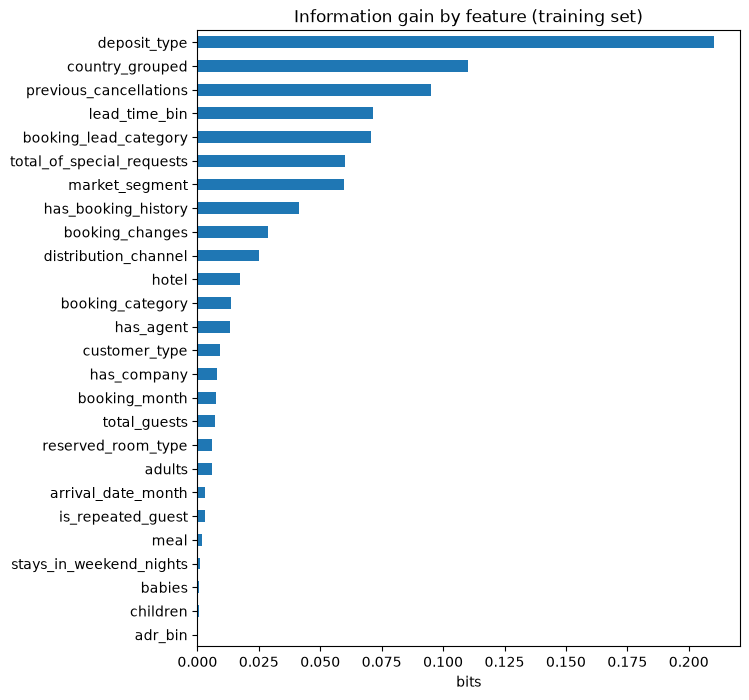

In [8]:
def best_feature(df, features, target="is_canceled", max_unique=20):
    """
    Most informative feature, ignoring columns with more than max_unique values
    (information gain rewards many small groups whether or not they are useful).
    """
    scores = {f: information_gain(df, f, target)
              for f in features if df[f].nunique() <= max_unique}
    winner = max(scores, key=scores.get)
    return winner, scores[winner]

feature, gain = best_feature(train, candidates)
print("excluded:", [f for f in candidates if train[f].nunique() > 20])
print(f"best feature: {feature}  ({gain:.4f} bits)")

usable = ranking[ranking["n_unique"] <= 20]
usable["information_gain"].sort_values().plot(kind="barh", figsize=(7, 8),
                                              title="Information gain by feature (training set)")
plt.xlabel("bits"); plt.show()

In [9]:
pairs = [
    ("lead_time_bin",          "booking_lead_category"),
    ("previous_cancellations", "historical_cancellation_rate"),
    ("previous_cancellations", "has_booking_history"),
    ("stays_in_week_nights",   "total_stay"),
    ("adults",                 "total_guests"),
    ("has_agent",              "booking_category"),
    ("arrival_date_month",     "booking_month"),
]

comparison = pd.DataFrame([{
    "original": o, "IG original": round(gains[o], 4),
    "engineered": e, "IG engineered": round(gains[e], 4),
    "engineered better?": gains[e] > gains[o],
} for o, e in pairs])

display(comparison)

,original,IG original,engineered,IG engineered,engineered better?
0,lead_time_bin,0.0714,booking_lead_category,0.0708,False
1,previous_cancellations,0.0951,historical_cancellation_rate,0.1084,True
2,previous_cancellations,0.0951,has_booking_history,0.0412,False
3,stays_in_week_nights,0.0128,total_stay,0.0185,True
4,adults,0.0059,total_guests,0.0073,True
5,has_agent,0.0131,booking_category,0.0136,True
6,arrival_date_month,0.0030,booking_month,0.0075,True


In [10]:
# Lab 2 asked whether Title was just Sex under another name. Same question here:
display(pd.crosstab(train["booking_category"], train["distribution_channel"]))
display(pd.crosstab(train["deposit_type"], train["market_segment"]))

distribution_channel,Corporate,Direct,GDS,TA/TO,Undefined
booking_category,,,,,
agent,937,4426,129,65880,2
company,3612,630,0,474,0
individual,531,5189,1,1180,3


market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
deposit_type,,,,,,,,
No Deposit,131,538,3781,8537,7887,14866,36103,2
Non Refund,0,0,246,13,6809,3895,51,0
Refundable,0,0,3,4,126,2,0,0
